# Sowing Success: How Machine Learning Helps Farmers Select the Best Crops

![Farmer in a field](farmer_in_a_field.jpg)

Measuring essential soil metrics such as nitrogen, phosphorous, potassium levels, and pH value is an important aspect of assessing soil condition. However, it can be an expensive and time-consuming process, which can cause farmers to prioritize which metrics to measure based on their budget constraints.

Farmers have various options when it comes to deciding which crop to plant each season. Their primary objective is to maximize the yield of their crops, taking into account different factors. One crucial factor that affects crop growth is the condition of the soil in the field, which can be assessed by measuring basic elements such as nitrogen and potassium levels. Each crop has an ideal soil condition that ensures optimal growth and maximum yield.

A farmer reached out to you as a machine learning expert for assistance in selecting the best crop for his field. They've provided you with a dataset called `soil_measures.csv`, which contains:

- `"N"`: Nitrogen content ratio in the soil
- `"P"`: Phosphorous content ratio in the soil
- `"K"`: Potassium content ratio in the soil
- `"pH"` value of the soil
- `"crop"`: categorical values that contain various crops (target variable).

Each row in this dataset represents various measures of the soil in a particular field. Based on these measurements, the crop specified in the `"crop"` column is the optimal choice for that field.  

In this project, you will build multi-class classification models to predict the type of `"crop"` and identify the single most importance feature for predictive performance.

In [18]:
# All required libraries are imported here for you.
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import accuracy_score

# Load the dataset
crops = pd.read_csv("soil_measures.csv")

# Write your code here
crops.head()

,N,P,K,ph,crop
0,90,42,43,6.502985,rice
1,85,58,41,7.038096,rice
2,60,55,44,7.840207,rice
3,74,35,40,6.980401,rice
4,78,42,42,7.628473,rice


In [19]:
# Start off by exploring the data. This includes various things such as:
# 1. Shape of the data
print("Shape of the Data is:", crops.shape)
# 2. Data Types of Data
# 3. Description of Data
print("\nDescription of Data Values:\n", crops.describe())
# 4. Analyse Missing Values
print("\nMissing Value Analysis:\n", crops.isna().sum())

Shape of the Data is: (2200, 5)

Description of Data Values:
                  N            P            K           ph
count  2200.000000  2200.000000  2200.000000  2200.000000
mean     50.551818    53.362727    48.149091     6.469480
std      36.917334    32.985883    50.647931     0.773938
min       0.000000     5.000000     5.000000     3.504752
25%      21.000000    28.000000    20.000000     5.971693
50%      37.000000    51.000000    32.000000     6.425045
75%      84.250000    68.000000    49.000000     6.923643
max     140.000000   145.000000   205.000000     9.935091

Missing Value Analysis:
 N       0
P       0
K       0
ph      0
crop    0
dtype: int64


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

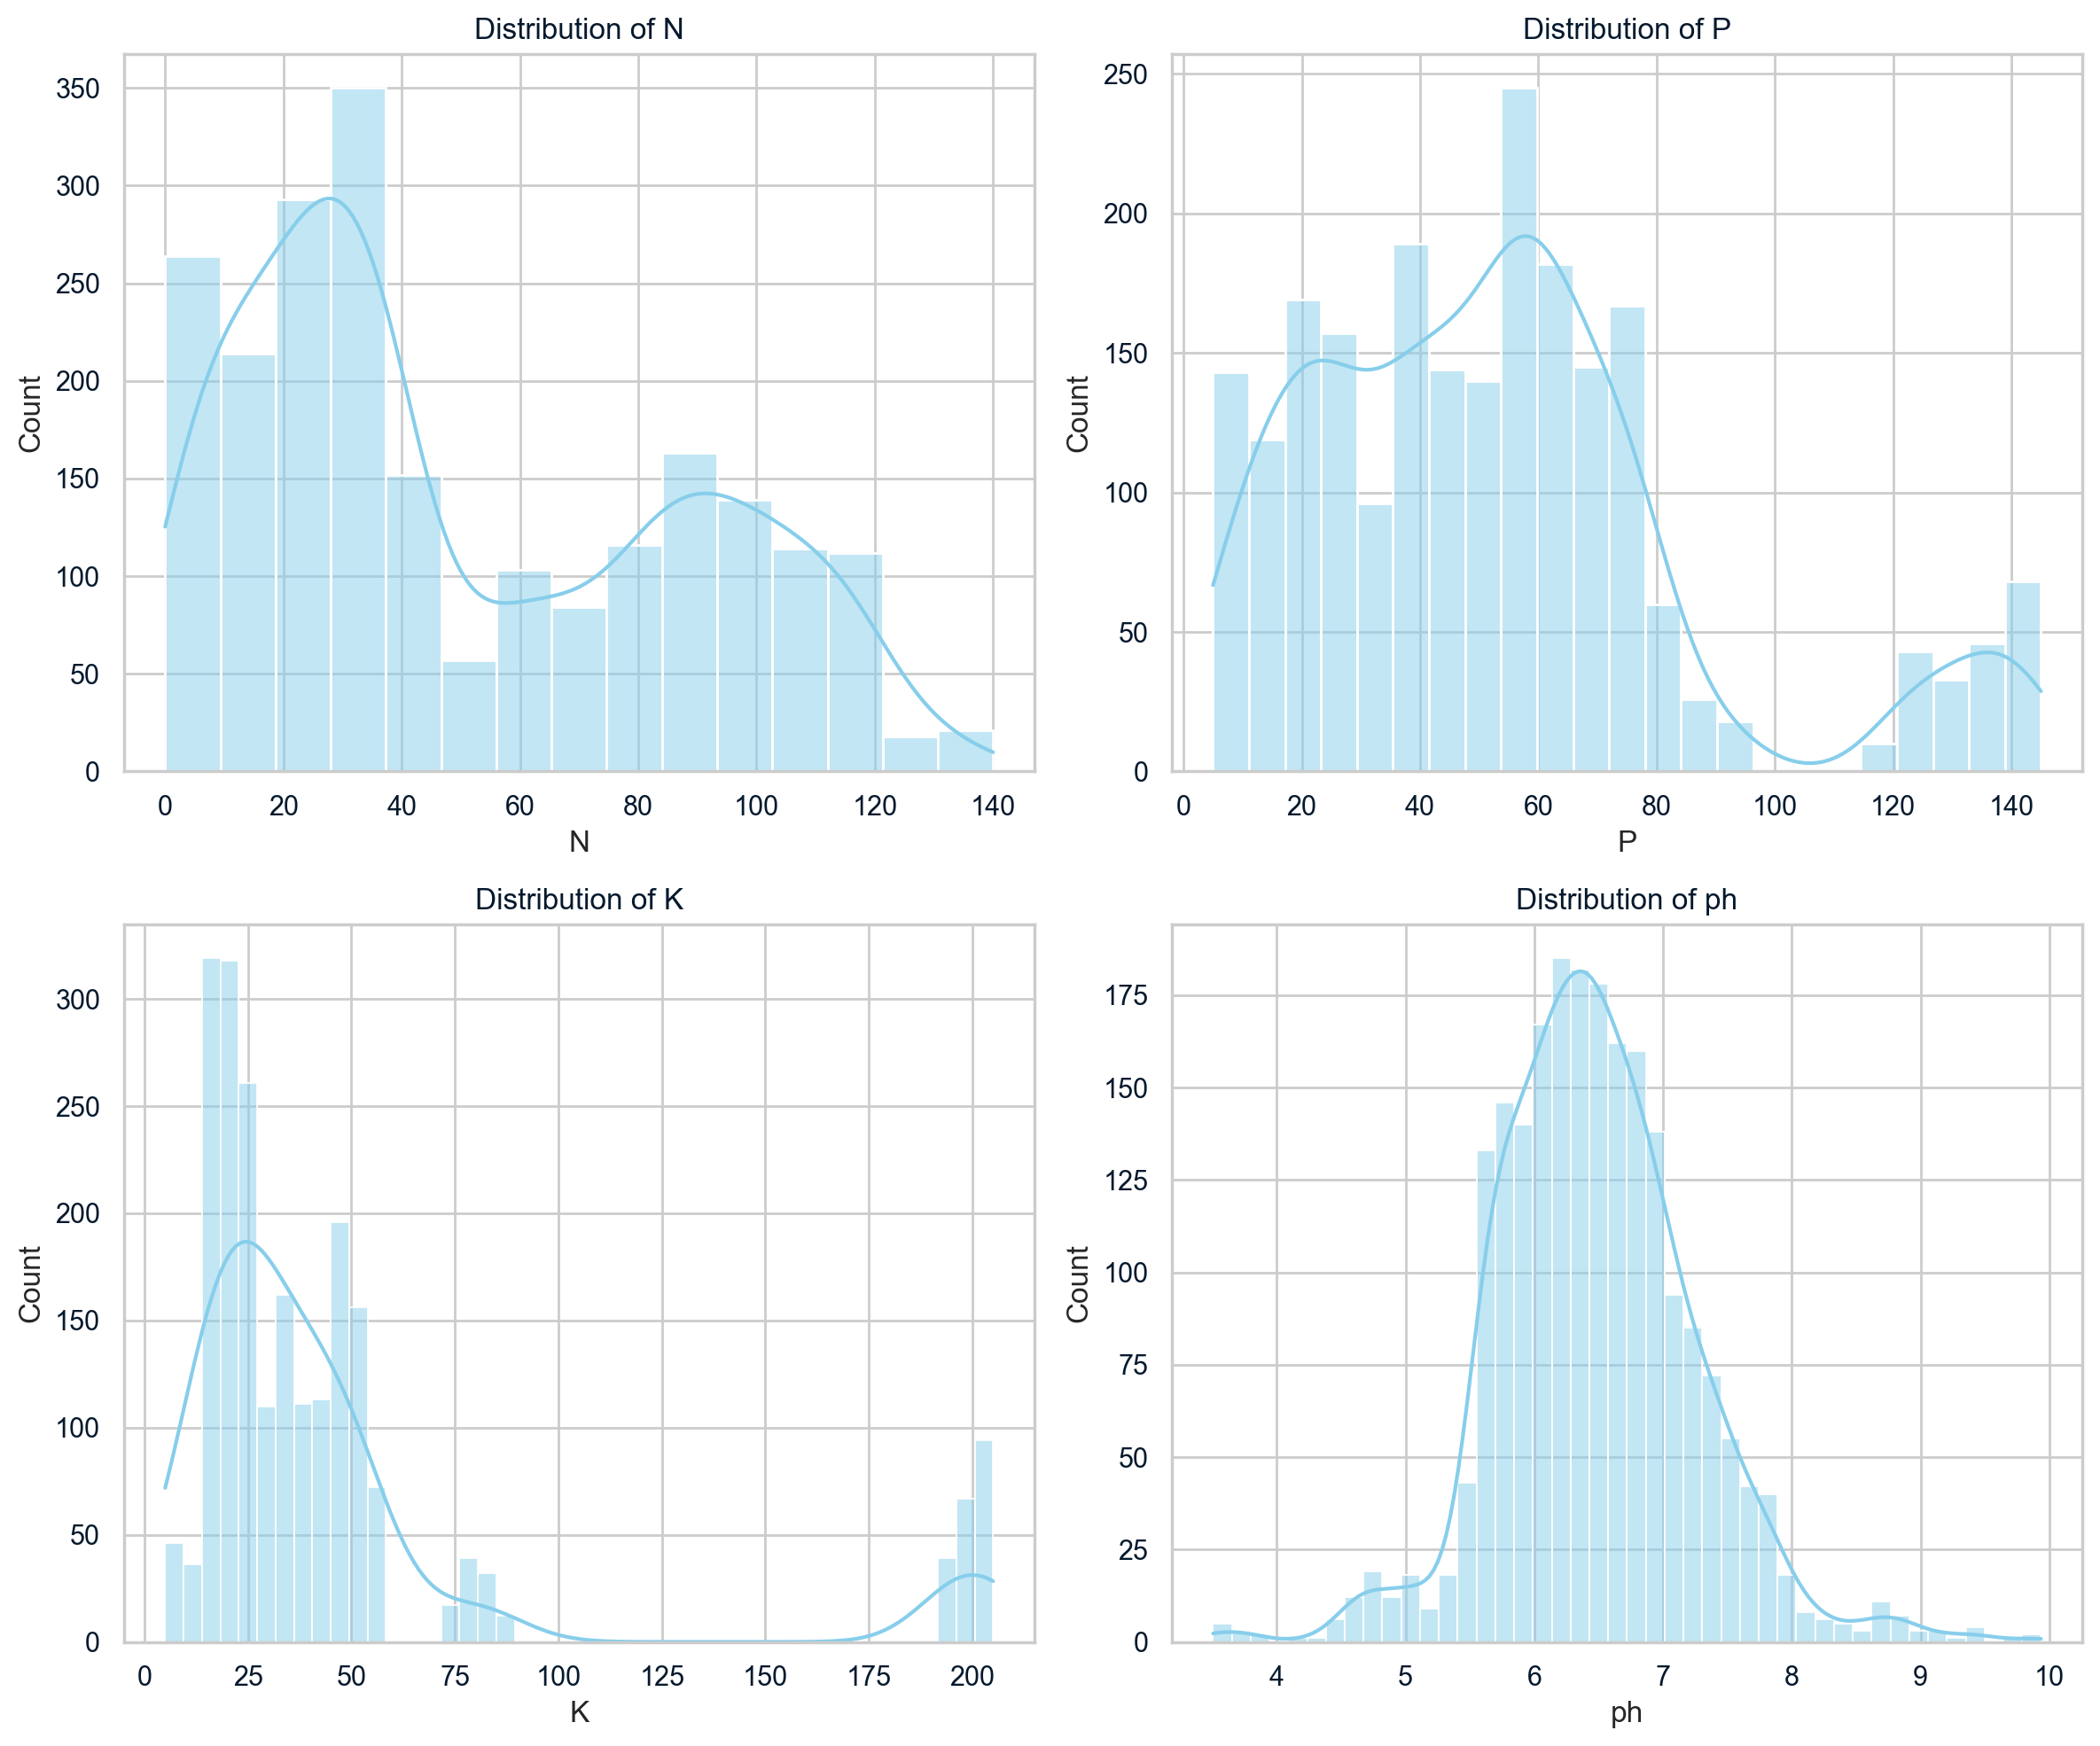

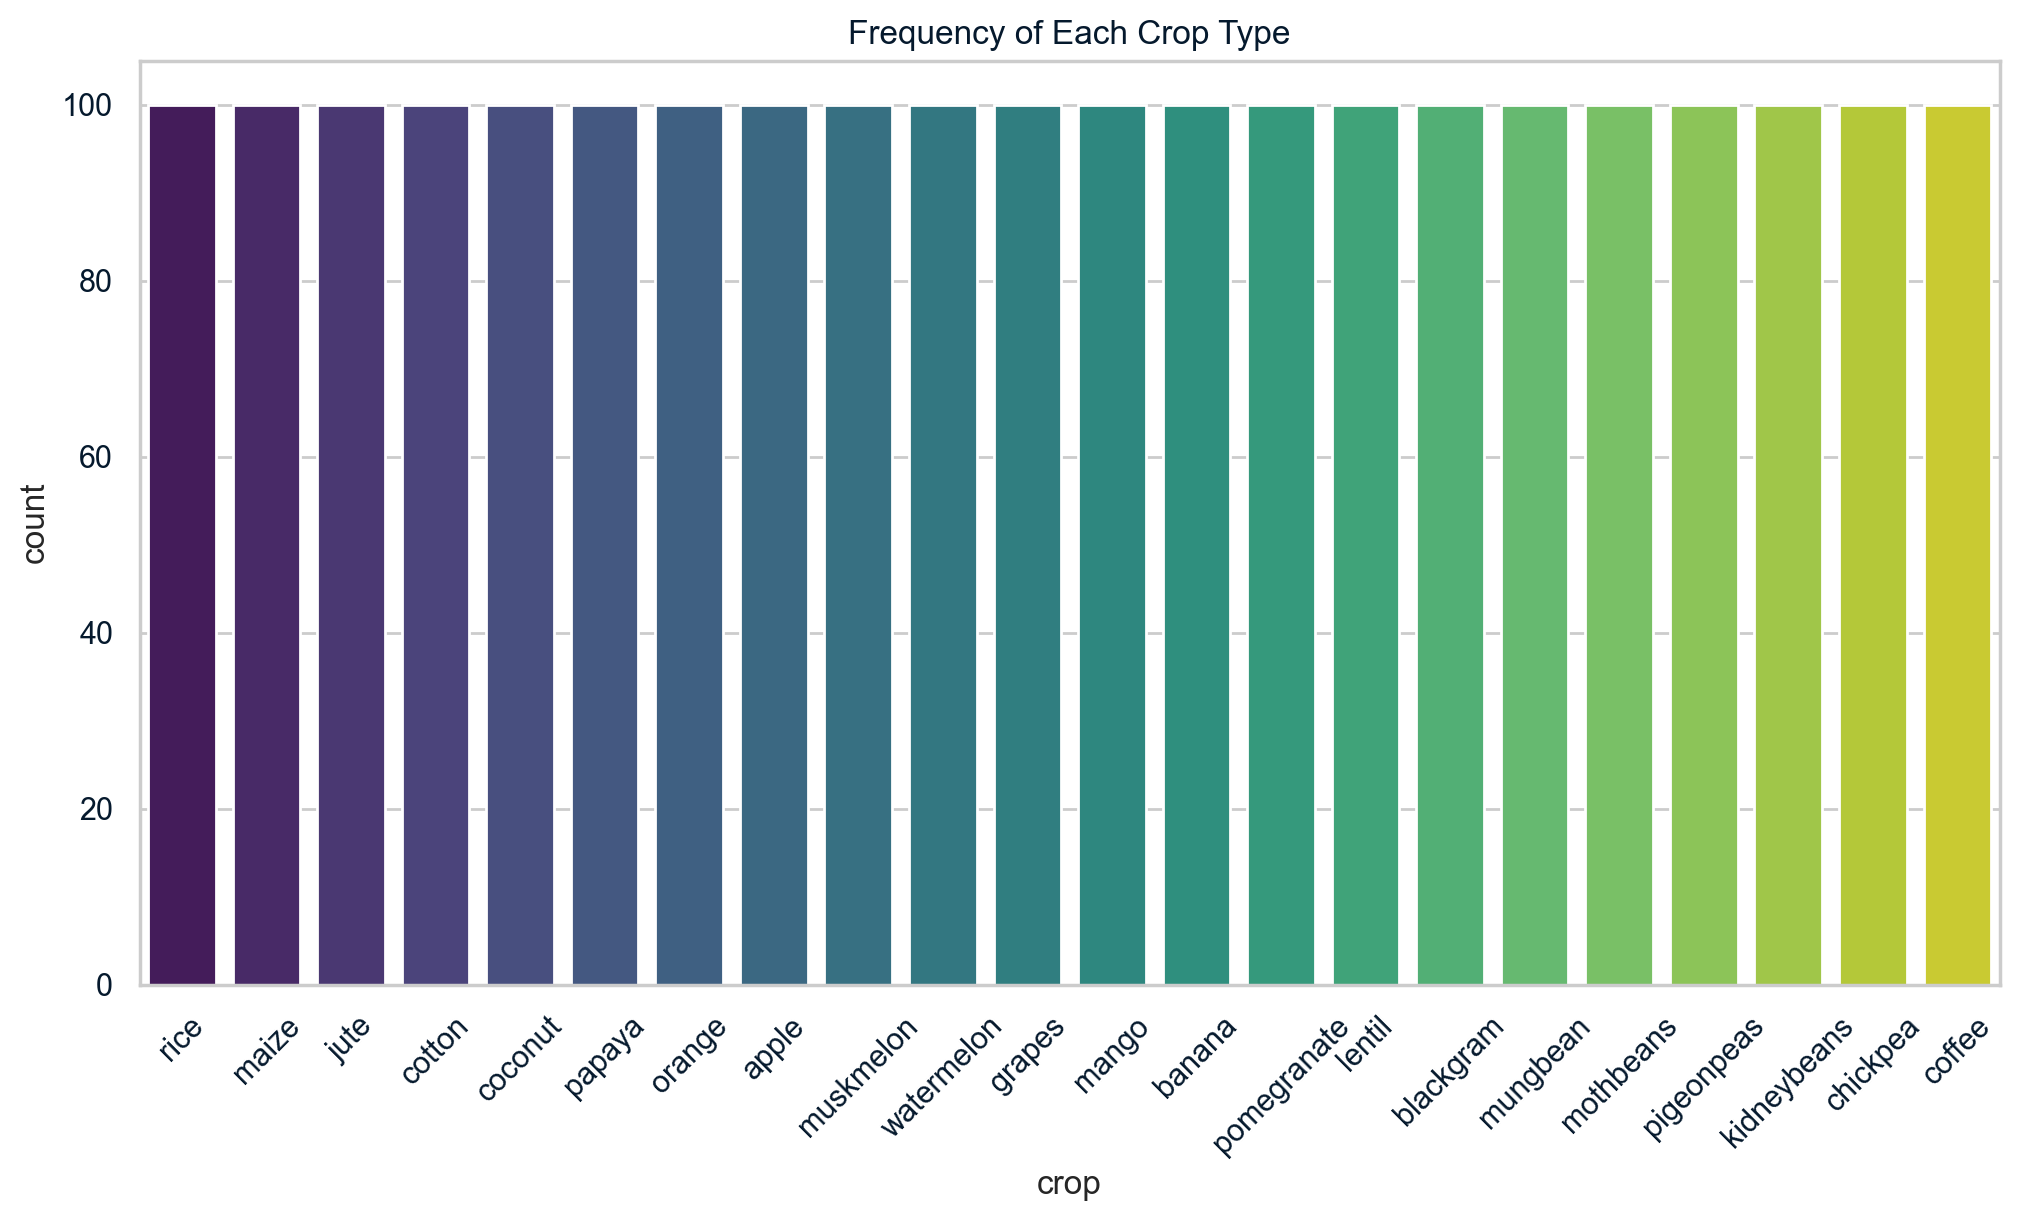

In [21]:
# from the above basic analysis we can see that the data is pretty healthy
# however that doesnt mean there is nothing else to do
# lets start off by doing some further analysis and visuals including

# 1. Univariate Analysis

# Set style
sns.set_theme(style="whitegrid")

# A. Distribution of Numerical Features (N, P, K, ph)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features = ['N', 'P', 'K', 'ph']

for i, feature in enumerate(features):
    row, col = divmod(i, 2)
    sns.histplot(crops[feature], kde=True, ax=axes[row, col], color='skyblue')
    axes[row, col].set_title(f'Distribution of {feature}')

plt.tight_layout()
plt.show()

# B. Target Variable Distribution (Crop counts)
plt.figure(figsize=(12, 6))
sns.countplot(data=crops, x='crop', order=crops['crop'].value_counts().index, palette='viridis')
plt.title('Frequency of Each Crop Type')
plt.xticks(rotation=45)
plt.show()

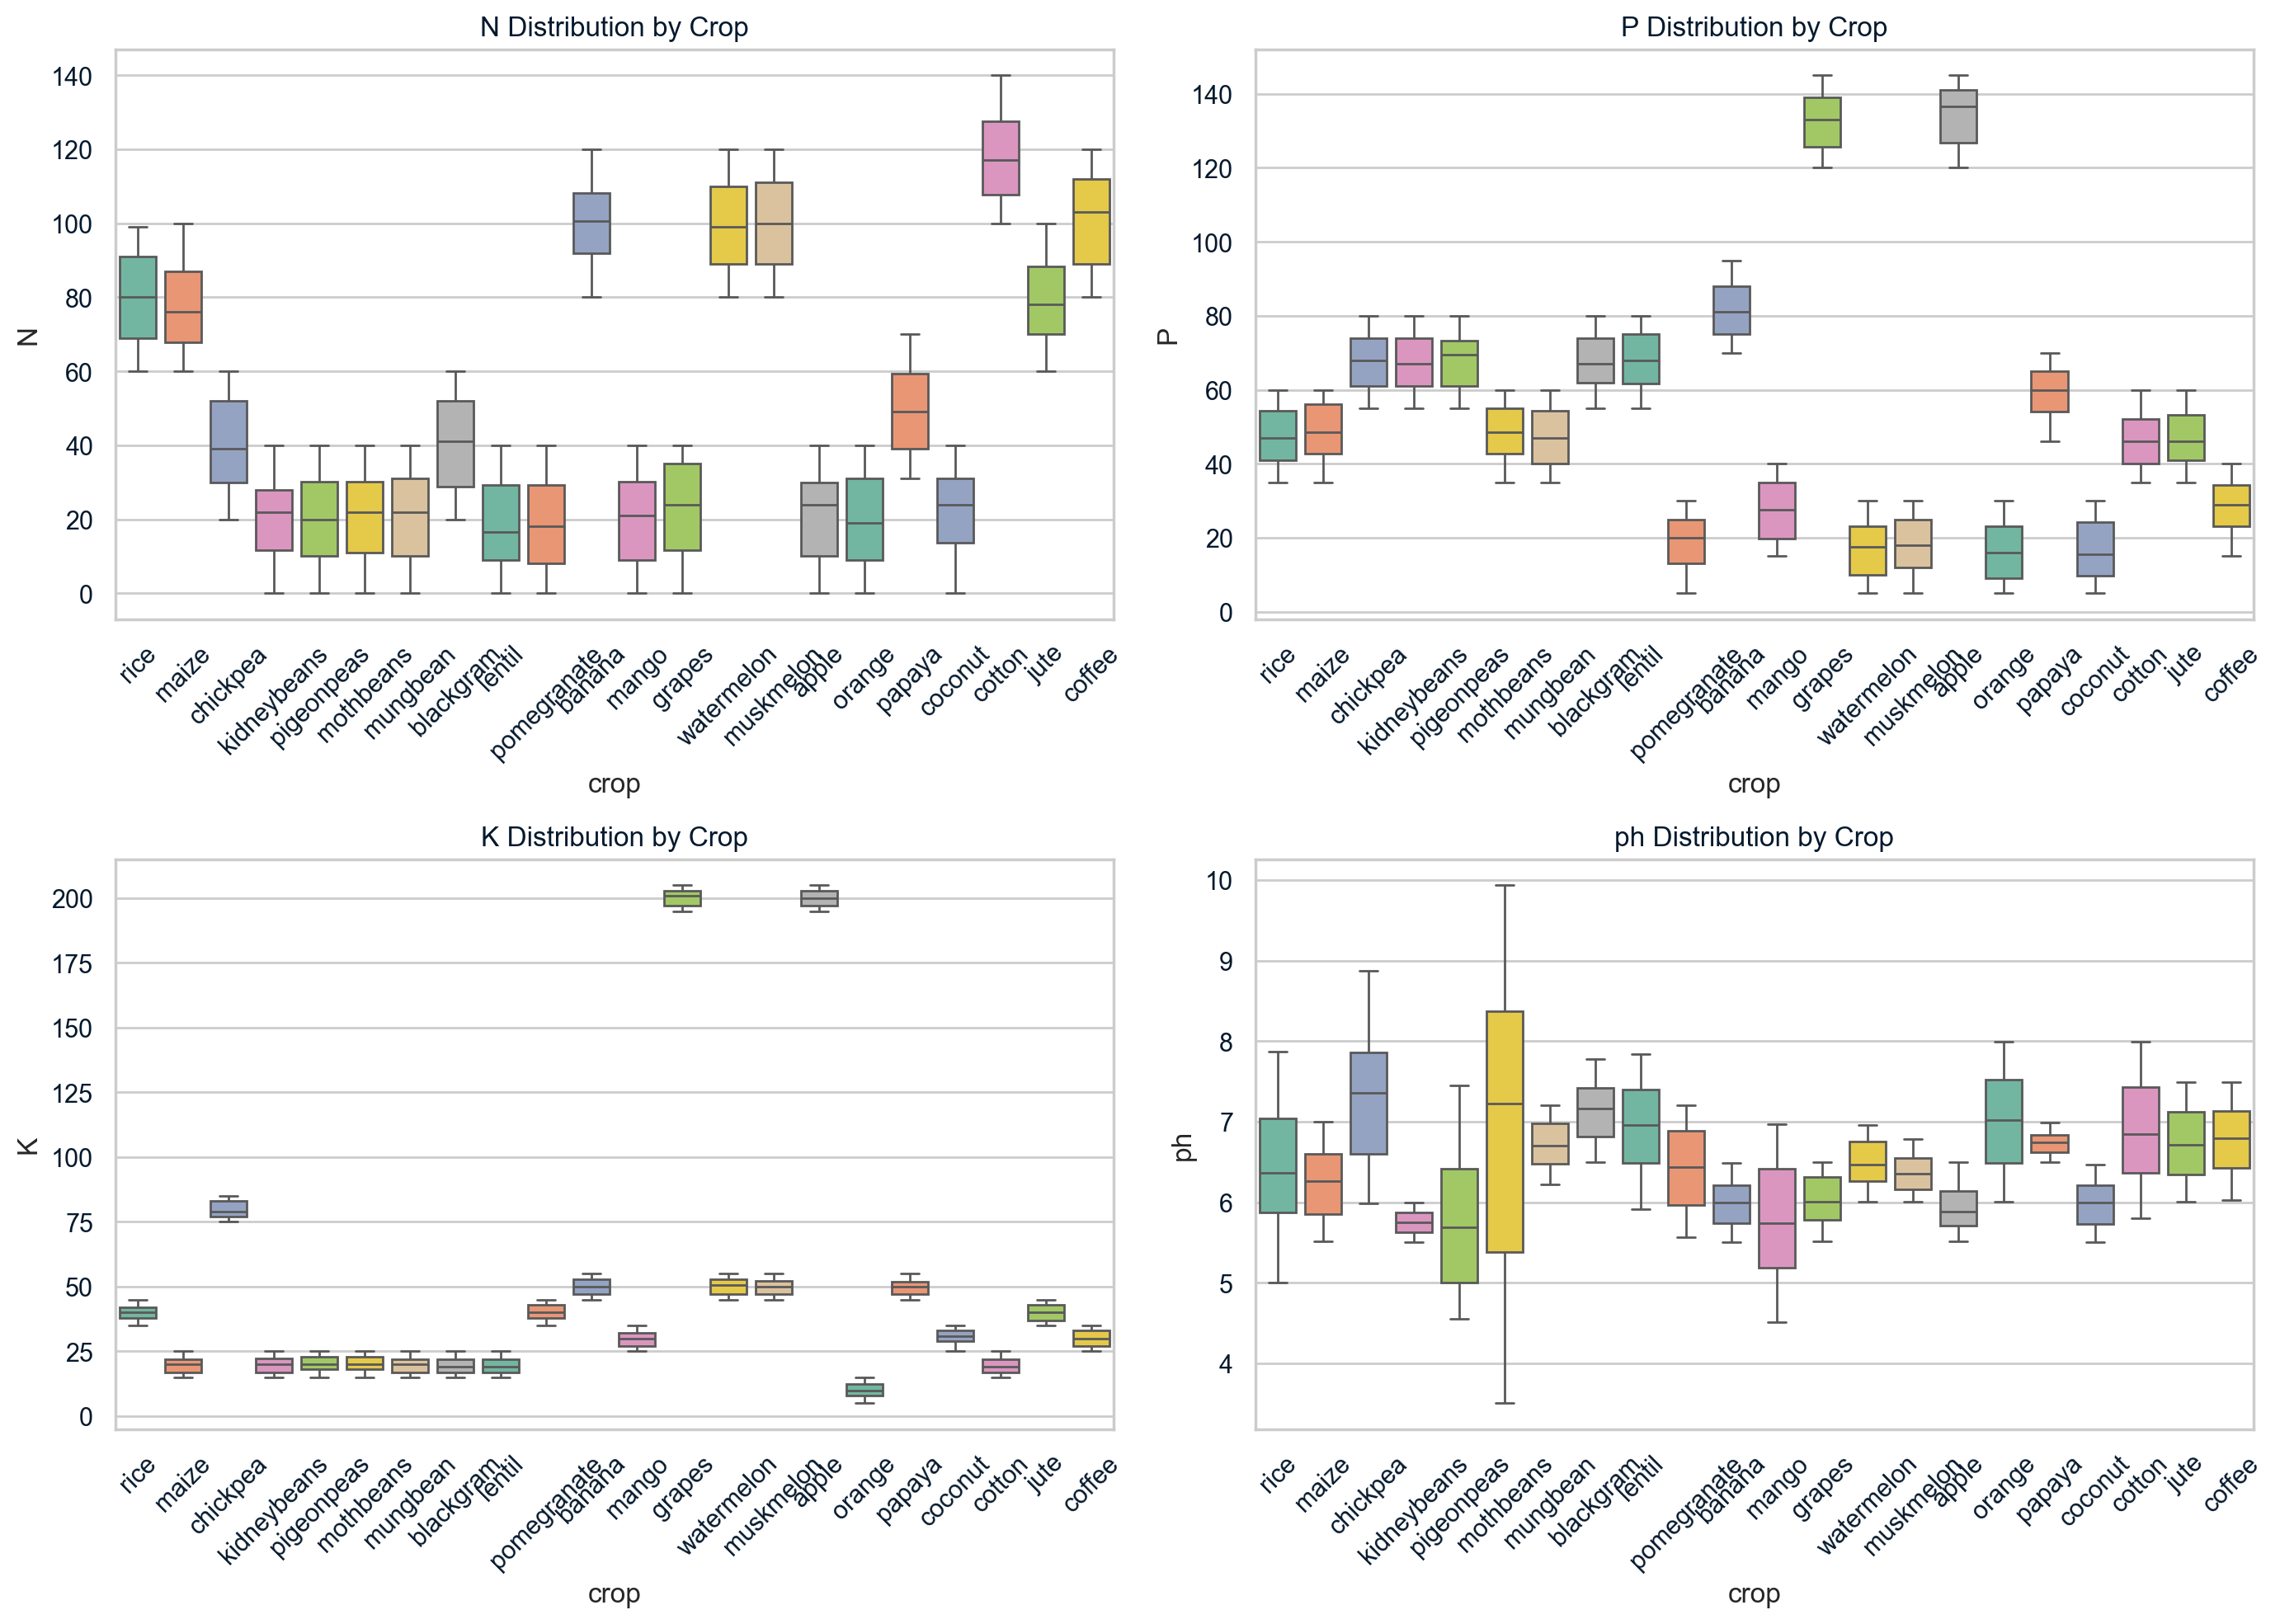

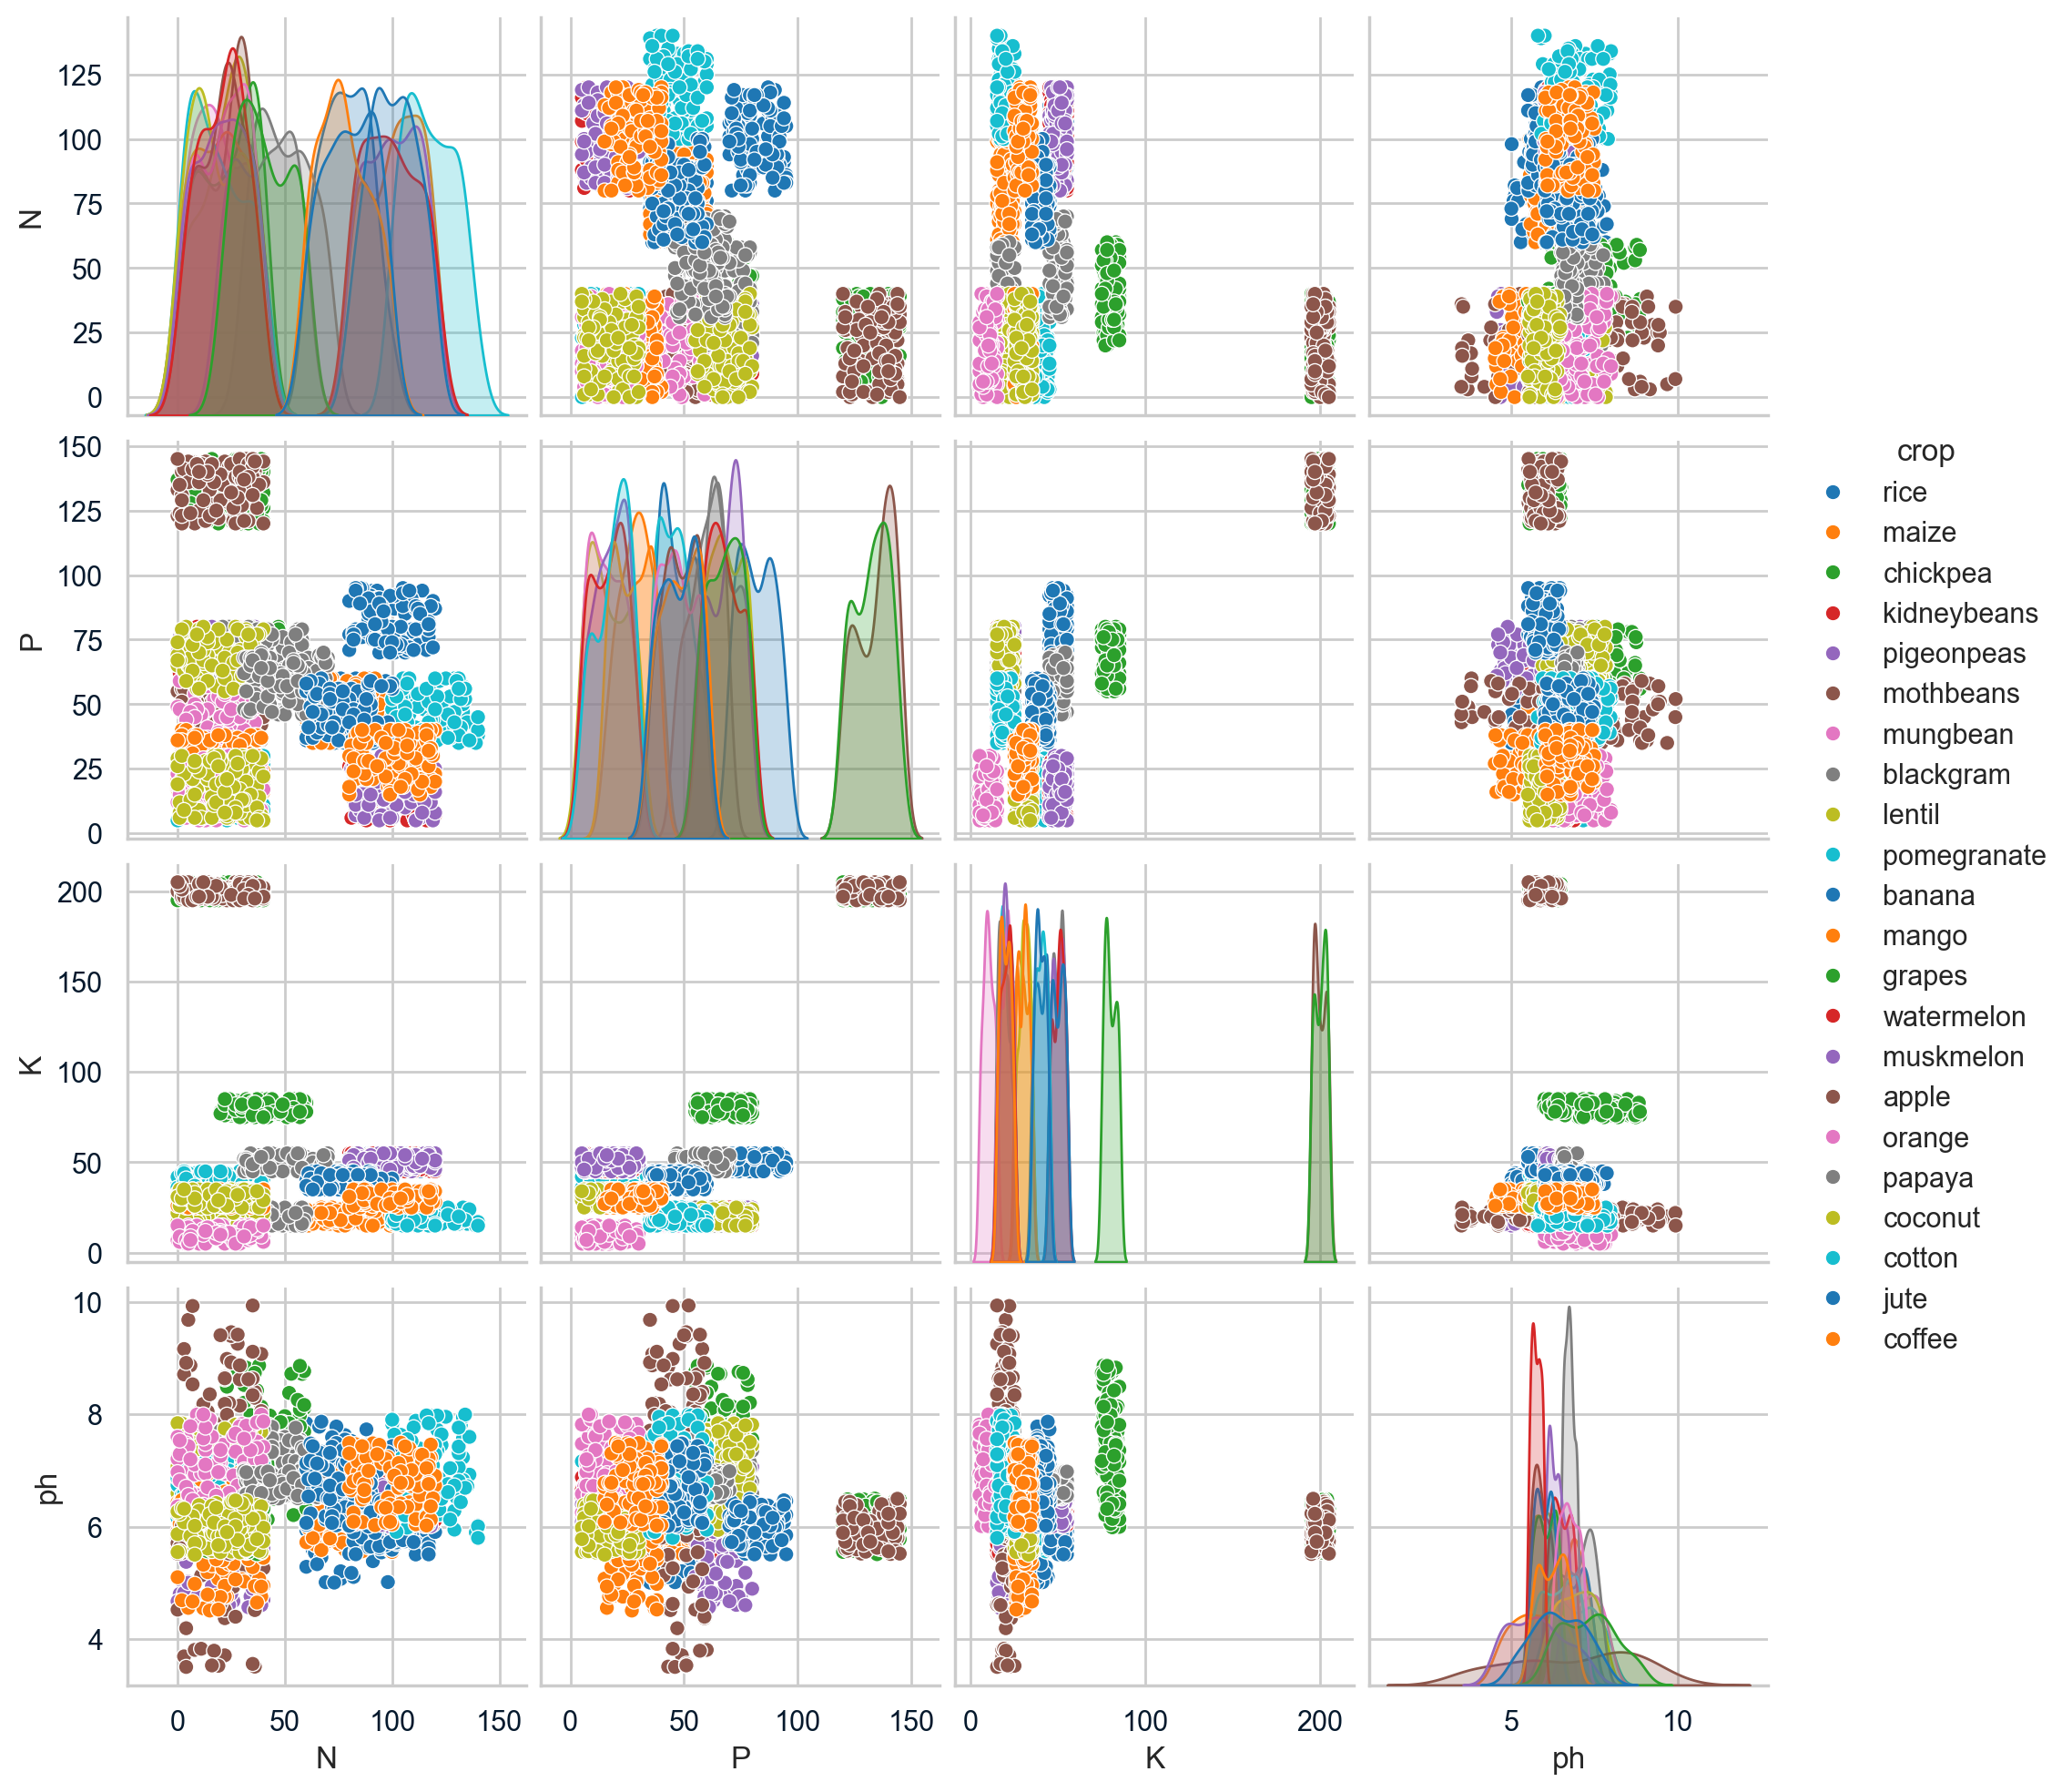

In [22]:
# 2. Multivariate Analysis

# A. Boxplots of Soil Features by Crop Type
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, feature in enumerate(features):
    row, col = divmod(i, 2)
    sns.boxplot(data=crops, x='crop', y=feature, ax=axes[row, col], palette='Set2')
    axes[row, col].set_title(f'{feature} Distribution by Crop')
    axes[row, col].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# B. Pairplot for Numerical Features colored by Crop
# (Note: If you have many crop classes, you can subset or keep hue=None if it gets too crowded)
sns.pairplot(crops, hue='crop', diag_kind='kde', palette='tab10')
plt.show()

           N         P         K        ph
N   1.000000 -0.231460 -0.140512  0.096683
P  -0.231460  1.000000  0.736232 -0.138019
K  -0.140512  0.736232  1.000000 -0.169503
ph  0.096683 -0.138019 -0.169503  1.000000


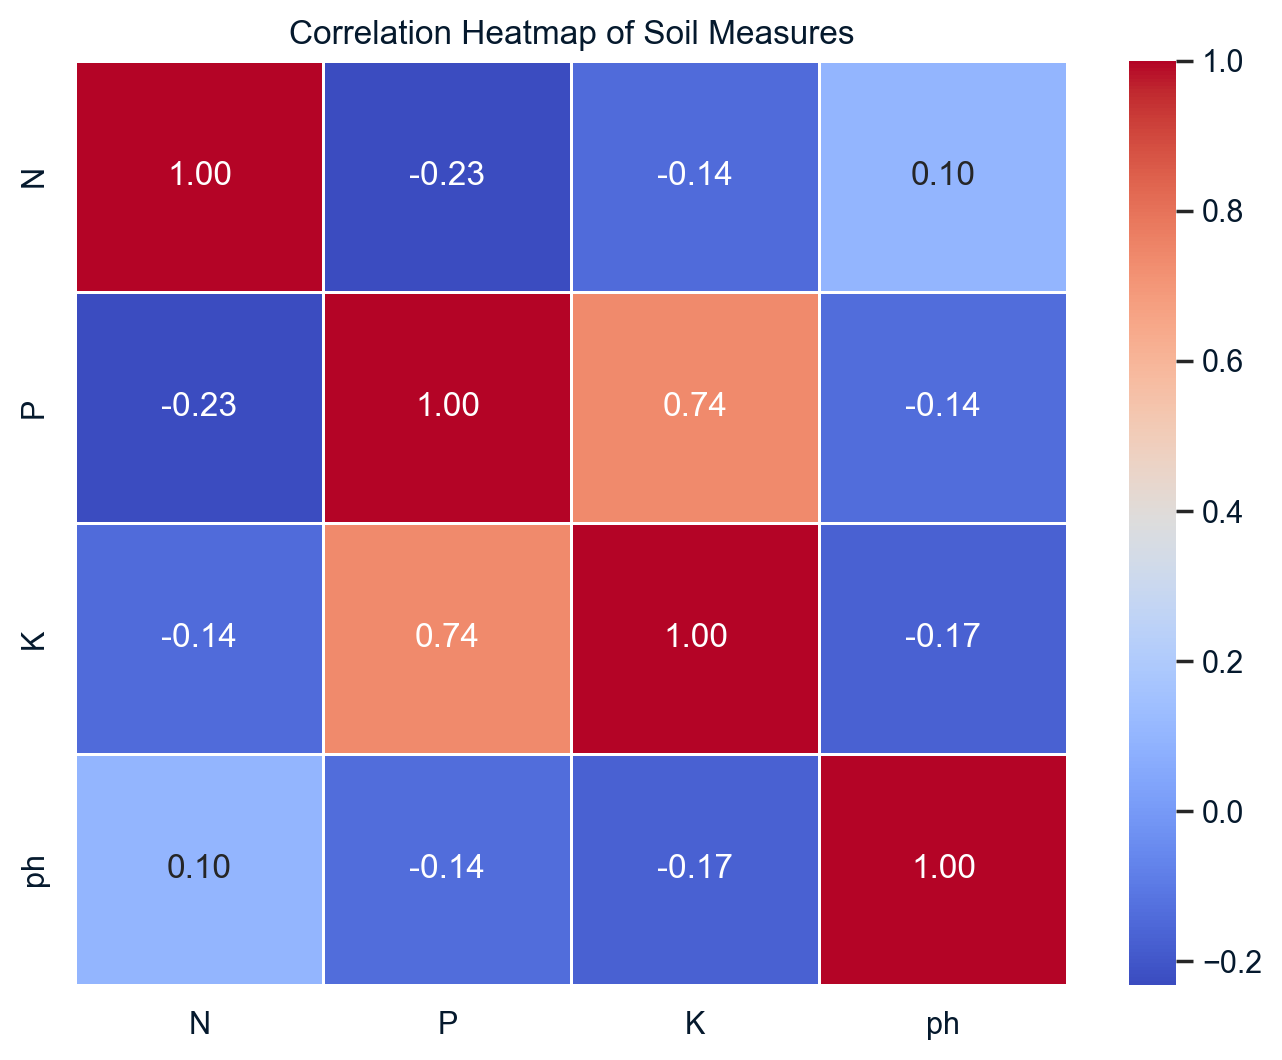

In [23]:
# 3. Correlation Analysis

# A. Calculate Correlation Matrix
numerical_cols = ['N', 'P', 'K', 'ph']
corr_matrix = crops[numerical_cols].corr()
print(corr_matrix)

# B. Plot Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Soil Measures')
plt.show()

In [16]:
# Next lets continue with splitting data, evaluating features and making predictions

# 1. Define features and target variable
X = crops.drop(columns="crop")
y = crops["crop"]

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Evaluate each feature independently
feature_performance = {}

for feature in ["N", "P", "K", "ph"]:
    # Train model using only one feature at a time
    lr = LogisticRegression(max_iter=2000, random_state=42)
    lr.fit(X_train[[feature]], y_train)
    
    # Predict and evaluate accuracy
    y_pred = lr.predict(X_test[[feature]])
    score = accuracy_score(y_test, y_pred)
    
    feature_performance[feature] = score
    print(f"Accuracy with {feature}: {score:.4f}")

# 4. Find the feature with the highest score
best_feature = max(feature_performance, key=feature_performance.get)
best_score = feature_performance[best_feature]

# 5. Create the required dictionary variable
best_predictive_feature = {best_feature: best_score}
print("\nBest Predictive Feature:", best_predictive_feature)

Accuracy with N: 0.1477
Accuracy with P: 0.1795


In [17]:
# 1. Train Logistic Regression using ALL features
all_features_model = LogisticRegression(max_iter=2000, random_state=42)
all_features_model.fit(X_train, y_train)

# 2. Evaluate accuracy with all features combined
y_pred_all = all_features_model.predict(X_test)
all_features_score = accuracy_score(y_test, y_pred_all)
print(f"Accuracy using ALL features combined: {all_features_score:.4f}")

# 3. Extract and display feature weights (coefficients)
# Note: Because this is a multi-class classification problem (multiple crop types), 
# .coef_ has a shape of (n_classes, n_features). We can map it cleanly into a DataFrame:
coefficients_df = pd.DataFrame(
    all_features_model.coef_, 
    columns=X.columns, 
    index=all_features_model.classes_
)

print("\nFeature Coefficients (Weights) per Crop Class:")
display(coefficients_df)

Accuracy using ALL features combined: 0.6636

Feature Coefficients (Weights) per Crop Class:


,N,P,K,ph
apple,-0.551402,-0.311635,1.322467,-2.879671
banana,0.259496,0.305914,0.018938,-3.004652
blackgram,-0.023929,0.734029,-0.806642,1.252154
chickpea,-0.270935,-0.227254,1.173226,-1.511380
coconut,-0.229558,-0.431782,0.498695,1.717625
coffee,0.469777,-0.472635,-0.218222,0.929237
cotton,0.645509,0.115254,-1.373185,-0.042273
grapes,-0.533436,-0.342260,1.339438,-2.395028
jute,0.243704,-0.117274,0.163223,0.366804
kidneybeans,-0.131640,0.788325,-0.689761,-1.240981
